In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Подключаем наш собственный созданный модуль биоинформатики
import sys
sys.path.append('./src')
from features import calculate_gc_content, generate_kmers

print("Пайплайн биоинформатики готов к работе!")


Пайплайн биоинформатики готов к работе!


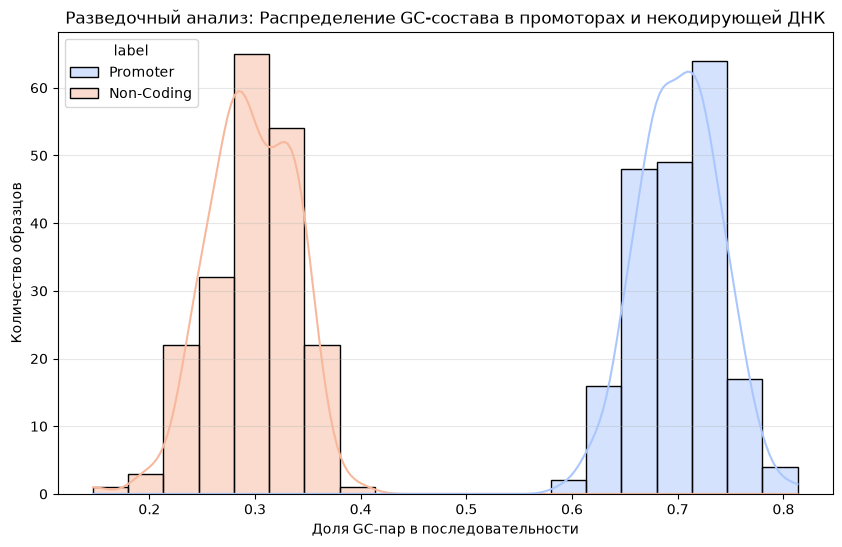

In [5]:
# 1. Генерируем синтетические последовательности ДНК
np.random.seed(42)
bases = ['A', 'C', 'G', 'T']

# Промоторы: повышенная вероятность для G и C (по 35% вместо 25%)
promoters = [''.join(np.random.choice(bases, size=150, p=[0.15, 0.35, 0.35, 0.15])) for _ in range(200)]
# Некодирующая (мусорная) ДНК: повышенная вероятность для A и T (по 35%)
junk_dna = [''.join(np.random.choice(bases, size=150, p=[0.35, 0.15, 0.15, 0.35])) for _ in range(200)]

# 2. Объединяем в общую таблицу Pandas
df = pd.DataFrame({
    'sequence': promoters + junk_dna,
    'label': ['Promoter'] * 200 + ['Non-Coding'] * 200
})

# 3. Применяем нашу функцию подсчета GC-состава из src/features.py
df['GC_Content'] = df['sequence'].apply(calculate_gc_content)

# 4. Строим график распределения (Разведочный анализ - EDA)
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='GC_Content', hue='label', kde=True, bins=20, palette='coolwarm', multiple='layer')
plt.title('Разведочный анализ: Распределение GC-состава в промоторах и некодирующей ДНК')
plt.xlabel('Доля GC-пар в последовательности')
plt.ylabel('Количество образцов')
plt.grid(axis='y', alpha=0.3)
plt.show()



=== ОТЧЕТ О КЛАССИФИКАЦИИ МОДЕЛИ ===
              precision    recall  f1-score   support

  Non-Coding       1.00      1.00      1.00        36
    Promoter       1.00      1.00      1.00        44

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



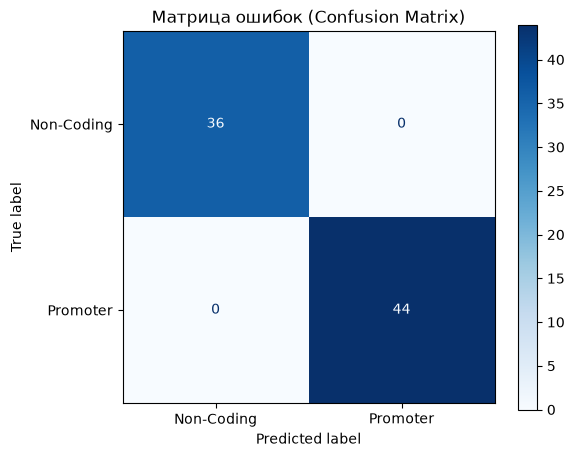

In [6]:
from sklearn.feature_extraction.text import CountVectorizer

# 1. Трансформируем последовательности ДНК в строки К-меров (через пробел)
# Модель CountVectorizer принимает текст, поэтому мы склеим "ATG", "TGC" в единую строку
df['kmer_text'] = df['sequence'].apply(lambda x: ' '.join(generate_kmers(x, k=3)))

# 2. Векторизуем текст: считаем частоту каждого триплета
cv = CountVectorizer()
X = cv.fit_transform(df['kmer_text']).toarray()
y = df['label'].map({'Promoter': 1, 'Non-Coding': 0}) # Переводим текст в 0 и 1 для ML

# 3. Делим выборку на обучающую и тестовую (80% на 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Создаем и обучаем модель Случайного Леса
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 5. Делаем предсказания и выводим метрики
y_pred = model.predict(X_test)
print("=== ОТЧЕТ О КЛАССИФИКАЦИИ МОДЕЛИ ===")
print(classification_report(y_test, y_pred, target_names=['Non-Coding', 'Promoter']))

# 6. Отрисовываем матрицу ошибок (Confusion Matrix)
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-Coding', 'Promoter'])
disp.plot(cmap='Blues', ax=plt.gca(), values_format='d')
plt.title('Матрица ошибок (Confusion Matrix)')
plt.show()


